# Option Greeks via Neural Pricers & Automatic Differentiation

Risk engines need sensitivities for every option in every scenario, and for models without a closed formula each one costs several repricings. Neural networks can price millions of options in milliseconds and give every Greek in a single backward pass. The catch is that a network can match prices well and still have poor derivatives. This notebook tests both claims on the real S&P 500 option market.

**What it does.** It trains neural networks to price options (Black–Scholes, and a Heston model calibrated to today's S&P 500 option market), takes every Greek from them by automatic differentiation, and measures how accurate and how fast those Greeks are on the real SPY option chain.

**Data.** A live SPY option chain snapshot (Yahoo Finance), Treasury bill and note yields for discounting (FRED), and SPY's trailing dividends.

**Methods.** Implied-volatility inversion, and an MLP pricer trained on prices only against a *differential* MLP trained on prices and Greeks (Huge & Savine, 2020).

A COS-method Heston pricer, validated against QuantLib and calibrated to the smile, feeds a neural Heston surrogate. Autograd Greeks are compared with analytic and bump-and-reprice Greeks.

**Key output.** Greek accuracy tables on the real chain, the calibrated Heston smile, speed comparisons, and the aggregated Greeks and scenario P&L of an option book.

## 1. Why neural pricers matter for risk

Risk engines need sensitivities (delta, gamma, vega, theta, rho) for every trade in every scenario: for hedging, for VaR, for XVA and for initial margin. For models without a closed form, each Greek costs several repricings by finite differences, so stochastic-volatility and exotic books quickly become too slow to risk-manage.

A neural network that has learnt the pricing function offers two things:

1. **Speed:** a forward pass prices millions of options in milliseconds.
2. **Greeks for free:** automatic differentiation gives exact derivatives *of the network* in one backward pass, with no bump size to tune.

The catch is that a network can match prices well and still have poor derivatives. **Differential machine learning** fixes this by training on the derivatives as well as the prices. This notebook tests both claims on real market data.

## 2. The models

**Black–Scholes with dividends.** With $m = S/K$, the call price per unit strike is a function $f(m, T, \sigma, r, q)$, so every Greek is a derivative of $f$:

| Greek | Analytic | From the network |
|---|---|---|
| Delta | $e^{-qT}N(d_1)$ | $\partial f/\partial m$ |
| Gamma | $e^{-qT}\varphi(d_1)/(S\sigma\sqrt{T})$ | $\partial^2 f/\partial m^2 \,/\, K$ |
| Vega | $S e^{-qT}\varphi(d_1)\sqrt{T}$ | $K\,\partial f/\partial \sigma$ |
| Theta | $-\partial C/\partial T$ | $-K\,\partial f/\partial T$ |
| Rho | $K T e^{-rT} N(d_2)$ | $K\,\partial f/\partial r$ |

Puts follow from put–call parity, $P = C - S e^{-qT} + K e^{-rT}$, so one network prices both.

**Heston (1993):** $dS = (r-q)S\,dt + \sqrt{v}\,S\,dW_1$, $dv = \kappa(\theta - v)dt + \sigma_v\sqrt{v}\,dW_2$, $d\langle W_1,W_2\rangle = \rho\,dt$. It produces the skew of index options through the correlation $\rho < 0$. Prices come from the **COS method** (Fang & Oosterlee, 2008), a Fourier-cosine expansion of the density that is fast and accurate for European options.

**Differential training.** The loss becomes $\text{MSE}(\hat f, f) + \lambda\,\text{MSE}(\nabla\hat f, \nabla f)$, where the gradient labels are the analytic first derivatives. Smooth activations (softplus) are used throughout so that second derivatives (gamma) exist.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch  # imported first: its OpenMP runtime must load before NumPy's

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import yfinance as yf
from scipy import stats
from scipy.optimize import brentq, least_squares

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

UNDERLYING = "SPY"
# expiries closest to these maturities
TARGET_DAYS = [7, 14, 30, 60, 91, 182, 365, 548]
# strikes between 75% and 125% of spot
MONEYNESS = (0.75, 1.25)
MAX_REL_SPREAD = 0.30  # (ask − bid) / mid
SEED = 5
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))
# double precision: Greeks are derivatives, keep them clean
torch.set_default_dtype(torch.float64)

print(
    f"torch {torch.__version__} · QuantLib {ql.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

torch 2.14.1+cu130 · QuantLib 1.44 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


GREEKS = ["delta", "gamma", "vega", "theta", "rho"]

## 4. Data: today's SPY option chain

The chain is a snapshot, so it is cached with its timestamp. Rerunning the notebook on another day gives another market; the method stays the same.

- **Spot and chain** from Yahoo Finance; mid = (bid + ask) / 2.
- **Rates:** Treasury yields from FRED (`DGS1MO` … `DGS2`), interpolated to each expiry and converted to continuous compounding.
- **Dividend yield:** trailing 12-month SPY dividends divided by spot, treated as continuous.

In [3]:
def fetch_chain():
    tk = yf.Ticker(UNDERLYING)
    spot = float(tk.history(period="5d")["Close"].iloc[-1])
    now = pd.Timestamp.now(tz="America/New_York").tz_localize(None)
    exps = pd.to_datetime(pd.Series(tk.options))
    days = (exps - now.normalize()).dt.days
    chosen = sorted({exps[(days - d).abs().idxmin()] for d in TARGET_DAYS})
    frames = []
    for e in chosen:
        ch = tk.option_chain(e.strftime("%Y-%m-%d"))
        for kind, df in (("call", ch.calls), ("put", ch.puts)):
            frames.append(df.assign(type=kind, expiry=e))
    chain = pd.concat(frames, ignore_index=True)
    chain["spot"], chain["snapshot"] = spot, now
    divs = tk.dividends
    divs.index = divs.index.tz_localize(None)
    chain["div_12m"] = divs[divs.index > now - pd.Timedelta(days=365)].sum()
    return chain.drop(columns=["lastTradeDate"], errors="ignore")


chain = cached("yahoo_spy_option_chain", fetch_chain, max_age_hours=24)
SPOT, SNAP = chain["spot"].iloc[0], pd.Timestamp(chain["snapshot"].iloc[0])
Q = np.log(1 + chain["div_12m"].iloc[0] / SPOT)

FRED_T = {
    "DGS1MO": 1 / 12,
    "DGS3MO": 0.25,
    "DGS6MO": 0.5,
    "DGS1": 1,
    "DGS2": 2,
}
fred_last = {
    t: fred.get_series(s).dropna().iloc[-1] for s, t in FRED_T.items()
}
rate_t, rate_v = np.array(list(fred_last)), np.log(
    1 + np.array(list(fred_last.values())) / 100
)
r_of = lambda T: np.interp(T, rate_t, rate_v)

chain["T"] = (
    pd.to_datetime(chain["expiry"]) + pd.Timedelta(hours=16) - SNAP
).dt.total_seconds() / (365.25 * 86400)
chain["mid"] = (chain["bid"] + chain["ask"]) / 2
chain["r"] = r_of(chain["T"])
chain["m"] = SPOT / chain["strike"]
print(
    f"Snapshot {SNAP:%Y-%m-%d %H:%M} ET · {UNDERLYING} {SPOT:.2f} · dividend"
    f" yield {Q:.2%} · {chain['expiry'].nunique()} expiries ·"
    f" {len(chain):,} quotes · r(1M) {r_of(1/12):.2%}, r(1Y) {r_of(1.0):.2%}"
)

Snapshot 2026-10-19 11:47 ET · SPY 769.96 · dividend yield 0.98% · 8 expiries · 2,960 quotes · r(1M) 4.09%, r(1Y) 4.39%


### 4.1 Cleaning and implied volatility

We keep two-sided quotes with a reasonable spread, strikes within 75–125% of spot, and **out-of-the-money** options only (puts below spot, calls above). OTM options carry the volatility information; in-the-money ones are mostly intrinsic value and trade wider. Implied volatility is solved from the mid with a bracketed root finder and compared with Yahoo's own figure.

In [4]:
def bs_price(S, K, T, sig, r, q, kind):
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sig**2) * T) / (sig * sqT)
    d2 = d1 - sig * sqT
    call = S * np.exp(-q * T) * stats.norm.cdf(d1) - K * np.exp(
        -r * T
    ) * stats.norm.cdf(d2)
    return np.where(
        kind == "call", call, call - S * np.exp(-q * T) + K * np.exp(-r * T)
    )


def bs_greeks(S, K, T, sig, r, q, kind):
    sqT = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + 0.5 * sig**2) * T) / (sig * sqT)
    d2 = d1 - sig * sqT
    disc_q, disc_r, pdf = np.exp(-q * T), np.exp(-r * T), stats.norm.pdf(d1)
    is_call = kind == "call"
    delta = np.where(
        is_call, disc_q * stats.norm.cdf(d1), disc_q * (stats.norm.cdf(d1) - 1)
    )
    gamma = disc_q * pdf / (S * sig * sqT)
    vega = S * disc_q * pdf * sqT
    theta_c = (
        -S * disc_q * pdf * sig / (2 * sqT)
        - r * K * disc_r * stats.norm.cdf(d2)
        + q * S * disc_q * stats.norm.cdf(d1)
    )
    theta = np.where(
        is_call, theta_c, theta_c + r * K * disc_r - q * S * disc_q
    )
    rho = np.where(
        is_call,
        K * T * disc_r * stats.norm.cdf(d2),
        -K * T * disc_r * stats.norm.cdf(-d2),
    )
    return pd.DataFrame({
        "delta": delta,
        "gamma": gamma,
        "vega": vega,
        "theta": theta,
        "rho": rho,
    })


def implied_vol(row):
    f = (
        lambda s: bs_price(
            SPOT, row["strike"], row["T"], s, row["r"], Q, row["type"]
        )
        - row["mid"]
    )
    try:
        return brentq(f, 1e-4, 5.0)
    except ValueError:
        return np.nan


otm = ((chain["type"] == "put") & (chain["strike"] < SPOT)) | (
    (chain["type"] == "call") & (chain["strike"] >= SPOT)
)
q_ok = (
    (chain["bid"] > 0)
    & (chain["ask"] > chain["bid"])
    & ((chain["ask"] - chain["bid"]) / chain["mid"] < MAX_REL_SPREAD)
)
opts = chain[
    otm
    & q_ok
    & chain["strike"].between(MONEYNESS[0] * SPOT, MONEYNESS[1] * SPOT)
    & (chain["T"] > 2 / 365)
].copy()
opts["iv"] = opts.apply(implied_vol, axis=1)
opts = opts.dropna(subset=["iv"]).reset_index(drop=True)
opts["expiry_label"] = pd.to_datetime(opts["expiry"]).dt.strftime("%d %b %y")
diff = (opts["iv"] - opts["impliedVolatility"]) * 100
print(
    f"{len(opts)} clean OTM quotes · our IV vs Yahoo's: median |gap|"
    f" {diff.abs().median():.2f} vol pts"
)
opts.groupby("expiry_label", sort=False).agg(
    T_years=("T", "first"),
    quotes=("strike", "size"),
    atm_iv=(
        "iv",
        lambda s: s.iloc[(opts.loc[s.index, "m"] - 1).abs().argmin()] * 100,
    ),
).round(3)

1043 clean OTM quotes · our IV vs Yahoo's: median |gap| 1.20 vol pts


,T_years,quotes,atm_iv
expiry_label,,,
26 Oct 26,0.02,103,11.28
30 Oct 26,0.03,194,13.59
20 Nov 26,0.09,140,13.97
18 Dec 26,0.17,168,14.33
15 Jan 27,0.24,74,14.40
31 Mar 27,0.45,156,15.66
30 Sep 27,0.95,131,18.20
16 Jun 28,1.66,77,19.97


## 5. Part A — a neural Black–Scholes pricer and its Greeks

### 5.1 Training data and the two networks

We sample 200,000 random points over a wide box (moneyness 0.6–1.6, maturity 1 day to 2.5 years, volatility 5–80%, rates 0–8%, dividend yield 0–4%) and label each with the analytic call price per unit strike **and** its five first derivatives. Two identical MLPs (four hidden layers of 96 softplus units) are trained.

Inside the network the raw inputs are mapped to log forward moneyness, total volatility $\sigma\sqrt{T}$ and standardised moneyness, the coordinates in which option prices are smooth; autograd differentiates through that mapping. The two networks differ only in their loss:

- **Price-only:** MSE on prices.
- **Differential:** MSE on prices + MSE on the derivatives, each scaled by its standard deviation.

Inputs are standardised inside the network, so autograd differentiates with respect to the raw financial variables.

In [5]:
BOX = {
    "m": (0.6, 1.6),
    "T": (1 / 365, 2.5),
    "sig": (0.05, 0.8),
    "r": (0.0, 0.08),
    "q": (0.0, 0.04),
}
rng = np.random.default_rng(SEED)
N_TRAIN = 200_000
Xs = np.column_stack([rng.uniform(*BOX[k], N_TRAIN) for k in BOX])
# more short maturities
Xs[:, 1] = np.exp(
    rng.uniform(np.log(BOX["T"][0]), np.log(BOX["T"][1]), N_TRAIN)
)
m_, T_, s_, r_, q_ = Xs.T
# K = 1: price per unit strike
y_price = bs_price(m_, 1.0, T_, s_, r_, q_, np.array("call"))
g = bs_greeks(m_, 1.0, T_, s_, r_, q_, np.array("call"))
# derivatives of f(m, T, sig, r, q) = C/K with K = 1: d/dm = delta, d/dT =
# −theta, d/dsig = vega, d/dr = rho, d/dq
y_grad = np.column_stack([
    g["delta"],
    -g["theta"],
    g["vega"],
    g["rho"],
    -m_
    * T_
    * np.exp(-q_ * T_)
    * stats.norm.cdf(
        (np.log(m_) + (r_ - q_ + 0.5 * s_**2) * T_) / (s_ * np.sqrt(T_))
    ),
])


class Pricer(torch.nn.Module):
    """
    MLP on financially natural features; softplus keeps second derivatives
    smooth.

    The raw inputs are (m = S/K, T, sigma, r, q). Inside the network they are
    mapped to log-moneyness,
    total volatility sigma*sqrt(T) and standardised moneyness
    ln(m)/(sigma*sqrt(T)), the coordinates in which
    option prices are smooth. Autograd differentiates through this mapping, so
    the Greeks stay with
    respect to the raw financial variables.
    """

    def __init__(self, X_sample, width=96, depth=4):
        super().__init__()
        z = self.features(torch.tensor(X_sample))
        self.register_buffer("mu", z.mean(dim=0))
        self.register_buffer("sd", z.std(dim=0))
        layers, d = [], z.shape[1]
        for _ in range(depth):
            layers += [torch.nn.Linear(d, width), torch.nn.Softplus(beta=2.0)]
            d = width
        self.net = torch.nn.Sequential(*layers, torch.nn.Linear(d, 1))

    @staticmethod
    def features(x):
        m, T, sig, r, q = x.unbind(dim=1)
        # log forward moneyness
        k = torch.log(m) + (r - q) * T
        w = sig * torch.sqrt(T)  # total volatility
        return torch.stack([k, w, k / w, torch.sqrt(T), r, q], dim=1)

    def forward(self, x):
        return self.net((self.features(x) - self.mu) / self.sd).squeeze(-1)


def fit(model, X, y, G=None, steps=8000, batch=2048, lr=2e-3, lam=1.0):
    X, y = torch.tensor(X), torch.tensor(y)
    G = None if G is None else torch.tensor(G)
    g_scale = None if G is None else G.std(dim=0)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    y_scale = y.std()
    for step in range(steps):
        idx = torch.randint(0, len(X), (batch,))
        xb = X[idx].clone().requires_grad_(G is not None)
        pred = model(xb)
        loss = torch.mean(((pred - y[idx]) / y_scale) ** 2)
        if G is not None:
            grad = torch.autograd.grad(pred.sum(), xb, create_graph=True)[0]
            loss = loss + lam * torch.mean(((grad - G[idx]) / g_scale) ** 2)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return model, loss.item()


t0 = time.time()
net_plain, l1 = fit(Pricer(Xs), Xs, y_price)
t1 = time.time()
net_diff, l2 = fit(Pricer(Xs), Xs, y_price, G=y_grad)
t2 = time.time()
print(
    f"Price-only net trained in {t1 - t0:.0f}s (loss {l1:.2e}) · differential"
    f" net in {t2 - t1:.0f}s (loss {l2:.2e})"
)

Price-only net trained in 132s (loss 2.62e-05) · differential net in 331s (loss 7.64e-04)


### 5.2 Greeks by automatic differentiation, on the real chain

For each clean SPY quote we feed the network the actual spot, strike, maturity, implied volatility, rate and dividend yield. Two backward passes then give all first derivatives and the gamma.

In [6]:
def nn_bs_greeks(net, S, K, T, sig, r, q, kind):
    """
    Price and Greeks of calls/puts from the call network, via autograd and put-
    call parity.
    """
    x = torch.tensor(
        np.column_stack([S / K, T, sig, r, q]), requires_grad=True
    )
    f = net(x)
    (grad,) = torch.autograd.grad(f.sum(), x, create_graph=True)
    (f_mm,) = torch.autograd.grad(grad[:, 0].sum(), x)
    f, grad, f_mm = (
        f.detach().numpy(),
        grad.detach().numpy(),
        f_mm[:, 0].numpy(),
    )
    call = K * f
    is_put = kind == "put"
    disc_q, disc_r = np.exp(-q * T), np.exp(-r * T)
    price = np.where(is_put, call - S * disc_q + K * disc_r, call)
    delta = grad[:, 0] - np.where(is_put, disc_q, 0)
    theta = -K * grad[:, 1] + np.where(
        is_put, r * K * disc_r - q * S * disc_q, 0
    )
    rho = K * grad[:, 3] - np.where(is_put, K * T * disc_r, 0)
    return price, pd.DataFrame({
        "delta": delta,
        "gamma": f_mm / K,
        "vega": K * grad[:, 2],
        "theta": theta,
        "rho": rho,
    })


args = (
    np.full(len(opts), SPOT),
    opts["strike"].values,
    opts["T"].values,
    opts["iv"].values,
    opts["r"].values,
    np.full(len(opts), Q),
    opts["type"].values,
)
true_g = bs_greeks(*args)
true_p = bs_price(*args)
res = {}
for name, net in [
    ("Price-only MLP", net_plain),
    ("Differential MLP", net_diff),
]:
    p, gk = nn_bs_greeks(net, *args)
    res[name] = gk
    res[name + " price"] = p

rows = []
for name in ["Price-only MLP", "Differential MLP"]:
    for subset, mask in [
        ("all expiries", np.ones(len(opts), bool)),
        ("T ≥ 30 days", opts["T"].values >= 30 / 365),
    ]:
        row = {
            "model": name,
            "quotes": subset,
            "price MAE ($)": np.mean(
                np.abs(res[name + " price"][mask] - true_p[mask])
            ),
        }
        for gname in GREEKS:
            err = (res[name][gname] - true_g[gname])[mask]
            row[f"{gname} error %"] = (
                np.mean(np.abs(err))
                / np.mean(np.abs(true_g[gname][mask]))
                * 100
            )
        rows.append(row)
bs_acc = pd.DataFrame(rows).set_index(["model", "quotes"])
print(
    "Greek errors: mean absolute error as % of the mean absolute analytic"
    " value"
)
bs_acc.round(3)

Greek errors: mean absolute error as % of the mean absolute analytic value


price MAE ($)  delta error %  gamma error %  \
model            quotes                                                      
Price-only MLP   all expiries           0.51          10.59          18.91   
                 T ≥ 30 days            0.53           5.28          13.27   
Differential MLP all expiries           0.20           4.76          11.98   
                 T ≥ 30 days            0.19           2.64           7.67   

                               vega error %  theta error %  rho error %  
model            quotes                                                  
Price-only MLP   all expiries          8.09          29.16         8.38  
                 T ≥ 30 days           6.46          11.04         6.98  
Differential MLP all expiries          1.89           6.51         2.20  
                 T ≥ 30 days           1.33           2.62         1.59

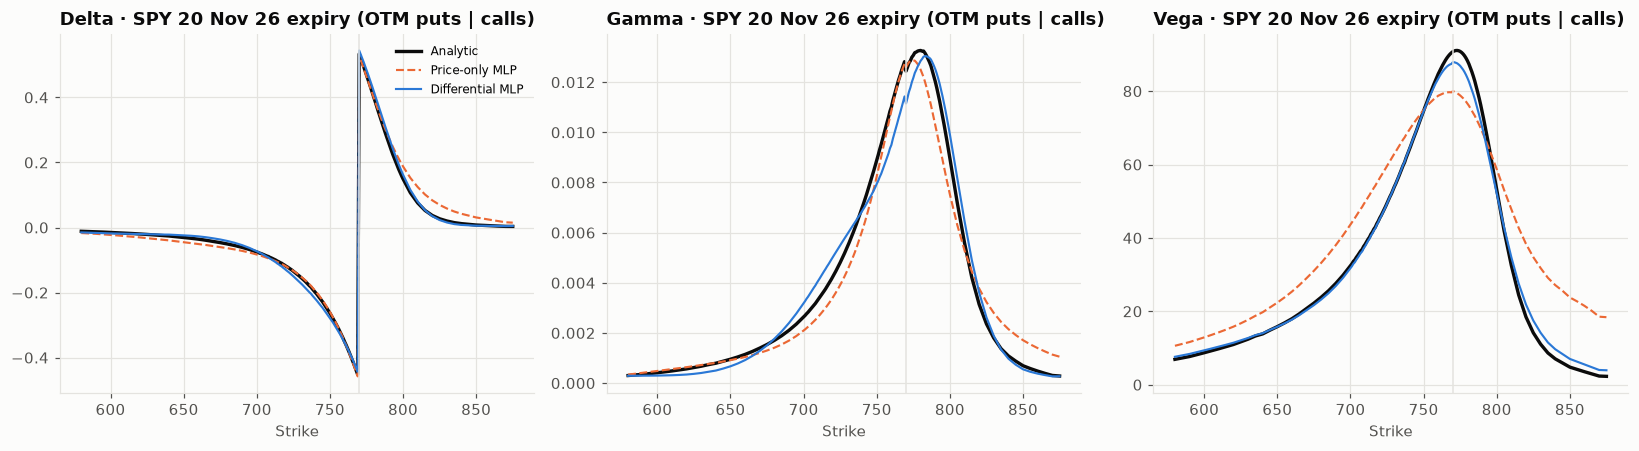

In [7]:
# --- Chart 1: delta and gamma across strikes for one expiry: analytic vs the
# two networks
lab = opts.loc[(opts["T"] - 30 / 365).abs().idxmin(), "expiry_label"]
sel = opts["expiry_label"] == lab
k_sel = opts.loc[sel, "strike"].values
order = np.argsort(k_sel)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, gname in zip(axes, ["delta", "gamma", "vega"]):
    ax.plot(
        k_sel[order],
        true_g.loc[sel, gname].values[order],
        color=INK,
        lw=2.2,
        label="Analytic",
    )
    ax.plot(
        k_sel[order],
        res["Price-only MLP"].loc[sel, gname].values[order],
        color=PALETTE[1],
        lw=1.4,
        ls="--",
        label="Price-only MLP",
    )
    ax.plot(
        k_sel[order],
        res["Differential MLP"].loc[sel, gname].values[order],
        color=PALETTE[0],
        lw=1.4,
        label="Differential MLP",
    )
    ax.axvline(SPOT, color=GRID, lw=1)
    ax.set_title(f"{gname.capitalize()} · SPY {lab} expiry (OTM puts | calls)")
    ax.set_xlabel("Strike")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_bs_greeks_analytic_vs_nn")
plt.show()

## 6. Part B — Heston calibrated to the SPY smile

### 6.1 A COS-method pricer, validated against QuantLib

The COS method prices thousands of options in one vectorised call. Before using it we check it against QuantLib's analytic Heston engine on a few contracts.

In [8]:
def heston_cf(u, T, r, q, v0, kappa, theta, sigma, rho):
    """
    Characteristic function of ln(S_T/S_0) (Albrecher et al. 'little trap'
    form, stable for long T).
    """
    iu = 1j * u
    a = kappa - rho * sigma * iu
    d = np.sqrt(a**2 + sigma**2 * (iu + u**2))
    g = (a - d) / (a + d)
    e = np.exp(-d * T)
    C = (
        kappa
        * theta
        / sigma**2
        * ((a - d) * T - 2 * np.log((1 - g * e) / (1 - g)))
    )
    D = (a - d) / sigma**2 * (1 - e) / (1 - g * e)
    return np.exp(iu * (r - q) * T + C + D * v0)


def heston_cos(S, K, T, r, q, v0, kappa, theta, sigma, rho, kind, N=256, L=12):
    """
    Vectorised COS prices (Fang & Oosterlee 2008). Puts by COS, calls by
    parity.
    """
    S, K, T, r, q, v0, kappa, theta, sigma, rho = (
        np.atleast_1d(np.asarray(v, float))[:, None]
        for v in (S, K, T, r, q, v0, kappa, theta, sigma, rho)
    )
    x = np.log(S / K)
    # expected integrated variance
    w = np.maximum(
        theta * T + (v0 - theta) * (1 - np.exp(-kappa * T)) / kappa, 1e-6
    )
    c1 = (r - q) * T - 0.5 * w
    a, b = x + c1 - L * np.sqrt(w), x + c1 + L * np.sqrt(w)
    k = np.arange(N)[None, :]
    u = k * np.pi / (b - a)
    # payoff coefficients of a put on y = ln(S_T/K), integrated over [a, 0]
    chi = (
        np.cos(u * (0 - a)) * 1
        - np.cos(u * (a - a)) * np.exp(a)
        + u * np.sin(u * (0 - a)) * 1
        - u * np.sin(u * (a - a)) * np.exp(a)
    ) / (1 + u**2)
    psi = np.where(
        k == 0,
        -a,
        (np.sin(u * (0 - a)) - np.sin(u * (a - a))) / np.where(k == 0, 1, u),
    )
    U = 2 / (b - a) * (psi - chi)
    cf = heston_cf(u, T, r, q, v0, kappa, theta, sigma, rho) * np.exp(
        1j * u * (x - a)
    )
    terms = np.real(cf) * U
    terms[:, 0] *= 0.5
    put = K[:, 0] * np.exp(-r[:, 0] * T[:, 0]) * terms.sum(axis=1)
    call = (
        put
        + S[:, 0] * np.exp(-q[:, 0] * T[:, 0])
        - K[:, 0] * np.exp(-r[:, 0] * T[:, 0])
    )
    return np.where(np.asarray(kind) == "call", call, put)


def heston_quantlib(S, K, T, r, q, v0, kappa, theta, sigma, rho, kind):
    today = ql.Date.todaysDate()
    ql.Settings.instance().evaluationDate = today
    dc = ql.Actual365Fixed()
    proc = ql.HestonProcess(
        ql.YieldTermStructureHandle(ql.FlatForward(today, r, dc)),
        ql.YieldTermStructureHandle(ql.FlatForward(today, q, dc)),
        ql.QuoteHandle(ql.SimpleQuote(S)),
        v0,
        kappa,
        theta,
        sigma,
        rho,
    )
    opt = ql.EuropeanOption(
        ql.PlainVanillaPayoff(
            ql.Option.Call if kind == "call" else ql.Option.Put, K
        ),
        ql.EuropeanExercise(today + int(round(T * 365))),
    )
    opt.setPricingEngine(ql.AnalyticHestonEngine(ql.HestonModel(proc)))
    return opt.NPV()


test_par = dict(v0=0.03, kappa=2.0, theta=0.04, sigma=0.6, rho=-0.7)
check = []
for K_, T_, kind in [
    (0.9 * SPOT, 30 / 365, "put"),
    (SPOT, 91 / 365, "call"),
    (1.1 * SPOT, 365 / 365, "call"),
    (0.8 * SPOT, 548 / 365, "put"),
]:
    qlp = heston_quantlib(SPOT, K_, T_, 0.04, Q, kind=kind, **test_par)
    cos = heston_cos(SPOT, K_, T_, 0.04, Q, kind=kind, **test_par)[0]
    check.append({
        "strike": K_,
        "T": T_,
        "type": kind,
        "QuantLib": qlp,
        "COS": cos,
        "abs diff": abs(qlp - cos),
    })
pd.DataFrame(check).round(5)

,strike,T,type,QuantLib,COS,abs diff
0,692.96,0.08,put,0.89,0.89,0.00
1,769.96,0.25,call,28.49,28.49,0.00
2,846.95,1.00,call,25.09,25.09,0.00
3,615.96,1.50,put,15.35,15.35,0.00


### 6.2 Calibration

Five parameters are fitted by least squares on price errors divided by Black–Scholes vega, which approximates implied-volatility errors and puts all strikes on the same footing. Each expiry gets the same total weight. Expiries shorter than three weeks are left out: a one-factor diffusion cannot produce their steep skew, and they would push the parameters to extremes. Their fit is still shown, out of sample.

In [9]:
# one-factor Heston cannot fit the weekly smiles; fit 3 weeks+
CAL_MIN_T = 20 / 365
cal_set = opts[opts["T"] >= CAL_MIN_T]
vega_w = np.maximum(true_g.loc[cal_set.index, "vega"].values, 0.05)
# equal weight per expiry
per_expiry = np.sqrt(
    cal_set.groupby("expiry_label")["strike"].transform("size").values
)
names = ["v0", "kappa", "theta", "sigma", "rho"]


def resid(p):
    model = heston_cos(
        SPOT,
        cal_set["strike"].values,
        cal_set["T"].values,
        cal_set["r"].values,
        Q,
        *p,
        kind=cal_set["type"].values,
    )
    return (model - cal_set["mid"].values) / vega_w / per_expiry


t0 = time.time()
cal = least_squares(
    resid,
    x0=[0.03, 2.0, 0.04, 0.8, -0.7],
    bounds=([1e-3, 0.05, 1e-3, 0.05, -0.999], [0.5, 15, 0.5, 3, 0.5]),
)
HESTON = dict(zip(names, cal.x))
opts["heston"] = heston_cos(
    SPOT,
    opts["strike"].values,
    opts["T"].values,
    opts["r"].values,
    Q,
    **HESTON,
    kind=opts["type"].values,
)


def iv_from_price(k, t, r, ty, p):
    try:
        return brentq(lambda s: bs_price(SPOT, k, t, s, r, Q, ty) - p, 1e-4, 5)
    # price outside no-arbitrage bounds
    except ValueError:
        return np.nan


opts["heston_iv"] = [
    iv_from_price(k, t, r, ty, p)
    for k, t, r, ty, p in zip(
        opts["strike"], opts["T"], opts["r"], opts["type"], opts["heston"]
    )
]
in_cal = opts["T"] >= CAL_MIN_T
rmse = (
    np.sqrt(
        np.nanmean(
            (opts.loc[in_cal, "heston_iv"] - opts.loc[in_cal, "iv"]) ** 2
        )
    )
    * 100
)
rmse_short = (
    np.sqrt(
        np.nanmean(
            (opts.loc[~in_cal, "heston_iv"] - opts.loc[~in_cal, "iv"]) ** 2
        )
    )
    * 100
)
print(
    f"Calibrated in {time.time() - t0:.1f}s · "
    + ", ".join(f"{k} = {v:.4f}" for k, v in HESTON.items())
    + " · Feller 2κθ/σ² ="
    f" {2 * HESTON['kappa'] * HESTON['theta'] / HESTON['sigma'] ** 2:.2f} ·"
    f" IV RMSE {rmse:.2f} vol pts on the calibrated expiries"
    f" ({rmse_short:.2f} pts on the weekly ones, not used)"
)

Calibrated in 9.2s · v0 = 0.0190, kappa = 9.6924, theta = 0.0430, sigma = 2.3074, rho = -0.6985 · Feller 2κθ/σ² = 0.16 · IV RMSE 0.86 vol pts on the calibrated expiries (6.45 pts on the weekly ones, not used)


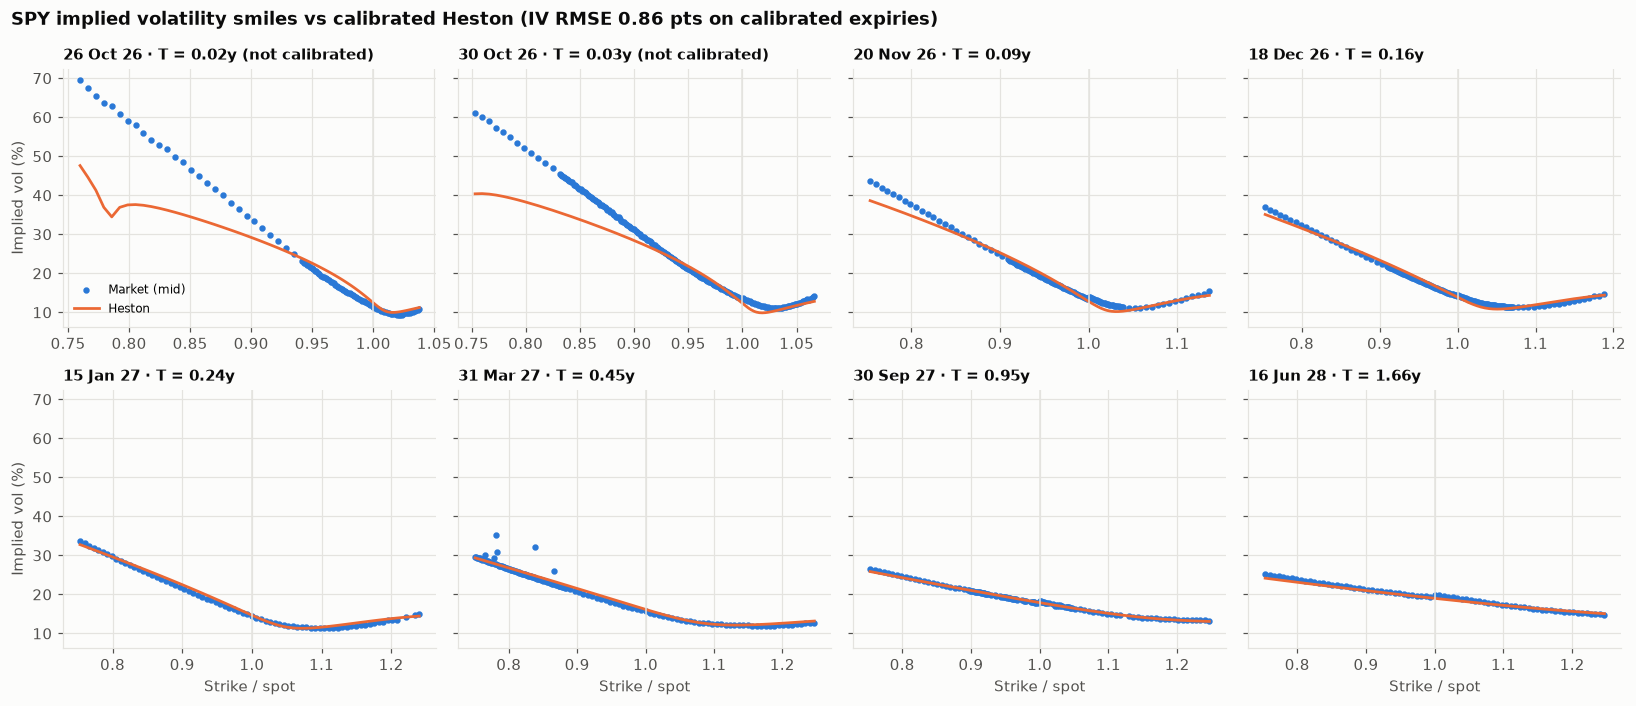

In [10]:
# --- Chart 2: market implied volatility vs calibrated Heston, by expiry
labels = list(dict.fromkeys(opts["expiry_label"]))
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for ax, lab_ in zip(axes.ravel(), labels):
    o = opts[opts["expiry_label"] == lab_].sort_values("strike")
    ax.scatter(
        o["strike"] / SPOT,
        o["iv"] * 100,
        s=10,
        color=PALETTE[0],
        label="Market (mid)",
    )
    ax.plot(
        o["strike"] / SPOT,
        o["heston_iv"] * 100,
        color=PALETTE[1],
        lw=1.8,
        label="Heston",
    )
    ax.set_title(
        f"{lab_} · T = {o['T'].iloc[0]:.2f}y"
        + ("" if o["T"].iloc[0] >= CAL_MIN_T else " (not calibrated)"),
        fontsize=10,
    )
    ax.axvline(1, color=GRID, lw=1)
for ax in axes[1]:
    ax.set_xlabel("Strike / spot")
for ax in axes[:, 0]:
    ax.set_ylabel("Implied vol (%)")
axes[0, 0].legend(fontsize=8)
for ax in axes.ravel()[len(labels) :]:
    ax.set_visible(False)
fig.suptitle(
    "SPY implied volatility smiles vs calibrated Heston (IV RMSE"
    f" {rmse:.2f} pts on calibrated expiries)",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "02_heston_smile_fit")
plt.show()

### 6.3 A neural Heston pricer

Heston has no closed-form Greeks, so this is where a surrogate pays off. We train a differential MLP on 150,000 COS prices with the model parameters themselves as inputs, sampled in a box around today's calibration. The derivative labels are the delta and the sensitivity to $v_0$, computed by small COS bumps.

The network then gives delta, gamma and the variance sensitivity $\partial P/\partial v_0$ by autograd, for any strike, maturity and parameter set in the box, at any rate on today's curve.

In [11]:
N_H = 150_000
hb = {
    "m": (0.7, 1.4),
    "T": (5 / 365, 1.6),
    "v0": (0.25 * HESTON["v0"], 3 * HESTON["v0"] + 0.01),
    "kappa": (0.5 * HESTON["kappa"], 1.5 * HESTON["kappa"]),
    "theta": (0.6 * HESTON["theta"], 1.5 * HESTON["theta"]),
    "sigma": (0.7 * HESTON["sigma"], 1.3 * HESTON["sigma"]),
    "rho": (max(-0.99, HESTON["rho"] - 0.15), min(0.0, HESTON["rho"] + 0.15)),
}
Xh = np.column_stack([rng.uniform(*hb[k], N_H) for k in hb])
Xh[:, 1] = np.exp(rng.uniform(np.log(hb["T"][0]), np.log(hb["T"][1]), N_H))


def cos_batch(X, dm=0.0, dv=0.0, chunk=20_000):
    out = []
    for i in range(0, len(X), chunk):
        x = X[i : i + chunk]
        out.append(
            heston_cos(
                x[:, 0] + dm,
                1.0,
                x[:, 1],
                r_of(x[:, 1]),
                Q,
                x[:, 2] + dv,
                x[:, 3],
                x[:, 4],
                x[:, 5],
                x[:, 6],
                kind=np.full(len(x), "call"),
            )
        )
    return np.concatenate(out)


t0 = time.time()
yh = cos_batch(Xh)
h_m, h_v = 1e-3, 1e-4
gh = np.column_stack([
    (cos_batch(Xh, dm=h_m) - cos_batch(Xh, dm=-h_m)) / (2 * h_m),
    (cos_batch(Xh, dv=h_v) - cos_batch(Xh, dv=-h_v)) / (2 * h_v),
])
label_time = time.time() - t0


class HestonPricer(Pricer):
    """
    Same idea for Heston: inputs (m, T, v0, kappa, theta, sigma, rho); features
    add log-moneyness,
    the expected total volatility over the option's life, and moneyness
    standardised by it.
    """

    @staticmethod
    def features(x):
        m, T, v0, kappa, theta, sigma, rho = x.unbind(dim=1)
        k = torch.log(m)
        w = torch.sqrt(
            theta * T + (v0 - theta) * (1 - torch.exp(-kappa * T)) / kappa
        )
        return torch.stack(
            [k, w, k / w, torch.sqrt(T), v0, kappa, theta, sigma, rho], dim=1
        )


net_h = HestonPricer(Xh, width=128, depth=4)
Xt, yt, Gt = torch.tensor(Xh), torch.tensor(yh), torch.tensor(gh)
opt = torch.optim.Adam(net_h.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 8000)
g_scale, y_scale = Gt.std(dim=0), yt.std()
t0 = time.time()
for step in range(8000):
    idx = torch.randint(0, N_H, (2048,))
    xb = Xt[idx].clone().requires_grad_(True)
    pred = net_h(xb)
    # d/dm and d/dv0
    grad = torch.autograd.grad(pred.sum(), xb, create_graph=True)[0][:, [0, 2]]
    loss = torch.mean(((pred - yt[idx]) / y_scale) ** 2) + torch.mean(
        ((grad - Gt[idx]) / g_scale) ** 2
    )
    opt.zero_grad()
    loss.backward()
    opt.step()
    sched.step()
print(
    f"Labels: {N_H:,} COS prices + bumps in {label_time:.0f}s · network"
    f" trained in {time.time() - t0:.0f}s (loss {loss.item():.2e})"
)

Labels: 150,000 COS prices + bumps in 94s · network trained in 460s (loss 7.75e-03)


In [12]:
# --- Heston Greeks on the real chain: autograd on the network vs COS bump-and-
# reprice
inside = opts["m"].between(*hb["m"]) & opts["T"].between(*hb["T"])
oh = opts[inside].reset_index(drop=True)
par = np.array([HESTON[k] for k in names])
Xc = np.column_stack(
    [SPOT / oh["strike"], oh["T"], np.tile(par, (len(oh), 1))]
)
K_, kind_, T_, rr = (
    oh["strike"].values,
    oh["type"].values,
    oh["T"].values,
    oh["r"].values,
)
disc_q, disc_r = np.exp(-Q * T_), np.exp(-rr * T_)

t0 = time.time()
x = torch.tensor(Xc, requires_grad=True)
f = net_h(x)
(gr,) = torch.autograd.grad(f.sum(), x, create_graph=True)
(fmm,) = torch.autograd.grad(gr[:, 0].sum(), x)
nn_time = time.time() - t0
f, gr, fmm = f.detach().numpy(), gr.detach().numpy(), fmm[:, 0].numpy()
is_put = kind_ == "put"
nn_h = pd.DataFrame({
    "price": K_ * f - np.where(is_put, SPOT * disc_q - K_ * disc_r, 0),
    "delta": gr[:, 0] - np.where(is_put, disc_q, 0),
    "gamma": fmm / K_,
    "dP/dv0": K_ * gr[:, 2],
})

t0 = time.time()
cos_p = lambda S=SPOT, v0=HESTON["v0"]: heston_cos(
    S,
    K_,
    T_,
    rr,
    Q,
    v0,
    HESTON["kappa"],
    HESTON["theta"],
    HESTON["sigma"],
    HESTON["rho"],
    kind=kind_,
)
hS, hv = 0.5, 1e-4
p0, pu, pd_ = cos_p(), cos_p(S=SPOT + hS), cos_p(S=SPOT - hS)
cos_h = pd.DataFrame({
    "price": p0,
    "delta": (pu - pd_) / (2 * hS),
    "gamma": (pu - 2 * p0 + pd_) / hS**2,
    "dP/dv0": (cos_p(v0=HESTON["v0"] + hv) - cos_p(v0=HESTON["v0"] - hv)) / (
        2 * hv
    ),
})
cos_time = time.time() - t0

long_ = oh["T"].values >= 30 / 365
h_acc = pd.DataFrame({
    g_: {
        "mean |error|": np.mean(np.abs(nn_h[g_] - cos_h[g_])),
        "error % (all)": (
            np.mean(np.abs(nn_h[g_] - cos_h[g_]))
            / np.mean(np.abs(cos_h[g_]))
            * 100
        ),
        "error % (T ≥ 30 days)": (
            np.mean(np.abs(nn_h[g_] - cos_h[g_])[long_])
            / np.mean(np.abs(cos_h[g_])[long_])
            * 100
        ),
    }
    for g_ in nn_h.columns
}).T
print(
    f"{len(oh)} options inside the training box · network price + 3 Greeks in"
    f" {nn_time * 1e3:.1f} ms vs COS bump-and-reprice (5 pricings) in"
    f" {cos_time * 1e3:.1f} ms"
)
h_acc.round(4)

966 options inside the training box · network price + 3 Greeks in 29.3 ms vs COS bump-and-reprice (5 pricings) in 523.3 ms


,mean |error|,error % (all),error % (T ≥ 30 days)
price,0.30,3.99,3.01
delta,0.01,8.03,4.45
gamma,0.00,24.05,10.10
dP/dv0,5.75,9.49,5.88


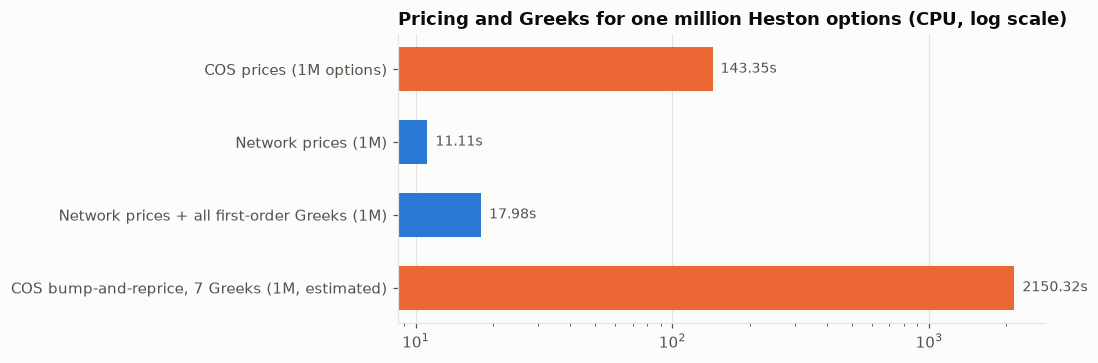

COS prices (1M options)                            143.35
Network prices (1M)                                 11.11
Network prices + all first-order Greeks (1M)        17.98
COS bump-and-reprice, 7 Greeks (1M, estimated)   2,150.32
Name: seconds, dtype: float64

In [13]:
# --- Speed at scale: one million Heston options
n_big = 1_000_000
Xb = np.column_stack([
    rng.uniform(*hb["m"], n_big),
    np.exp(rng.uniform(np.log(30 / 365), np.log(1.5), n_big)),
    np.tile(par, (n_big, 1)),
])
t0 = time.time()
with torch.no_grad():
    _ = net_h(torch.tensor(Xb))
t_nn = time.time() - t0
t0 = time.time()
_ = cos_batch(Xb[:50_000])
t_cos = (time.time() - t0) * n_big / 50_000
xg = torch.tensor(Xb[:200_000], requires_grad=True)
t0 = time.time()
ff = net_h(xg)
(gg,) = torch.autograd.grad(ff.sum(), xg)
t_grad = (time.time() - t0) * 5
speed = pd.Series({
    "COS prices (1M options)": t_cos,
    "Network prices (1M)": t_nn,
    "Network prices + all first-order Greeks (1M)": t_grad,
    "COS bump-and-reprice, 7 Greeks (1M, estimated)": t_cos * 15,
}).rename("seconds")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(
    speed.index[::-1],
    speed.values[::-1],
    color=[PALETTE[1], PALETTE[0], PALETTE[0], PALETTE[1]][::-1],
    height=0.6,
)
for y, v in enumerate(speed.values[::-1]):
    ax.text(v, y, f"  {v:.2f}s", va="center", fontsize=9, color=INK_2)
ax.set_xscale("log")
ax.set_title(
    "Pricing and Greeks for one million Heston options (CPU, log scale)"
)
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "03_speed_comparison")
plt.show()
speed.round(3)

## 7. From trades to a book: aggregated Greeks and scenario P&L

A hypothetical dealer book on SPY options: short downside puts, a long call spread and a short at-the-money straddle. Its Greeks come from the neural Heston pricer. Its P&L under spot and variance shocks is computed two ways: full revaluation with the network, and the delta–gamma–vega Taylor expansion a risk system would use. The gap between the two is the non-linearity that the expansion misses.

Book value $-180,263 · delta 2,246 shares ($1.73mm) · gamma -201.1 shares per $ · dV/dv0 $-3,592,611 per unit variance (≈ $-9,907 per vol point of √v0)


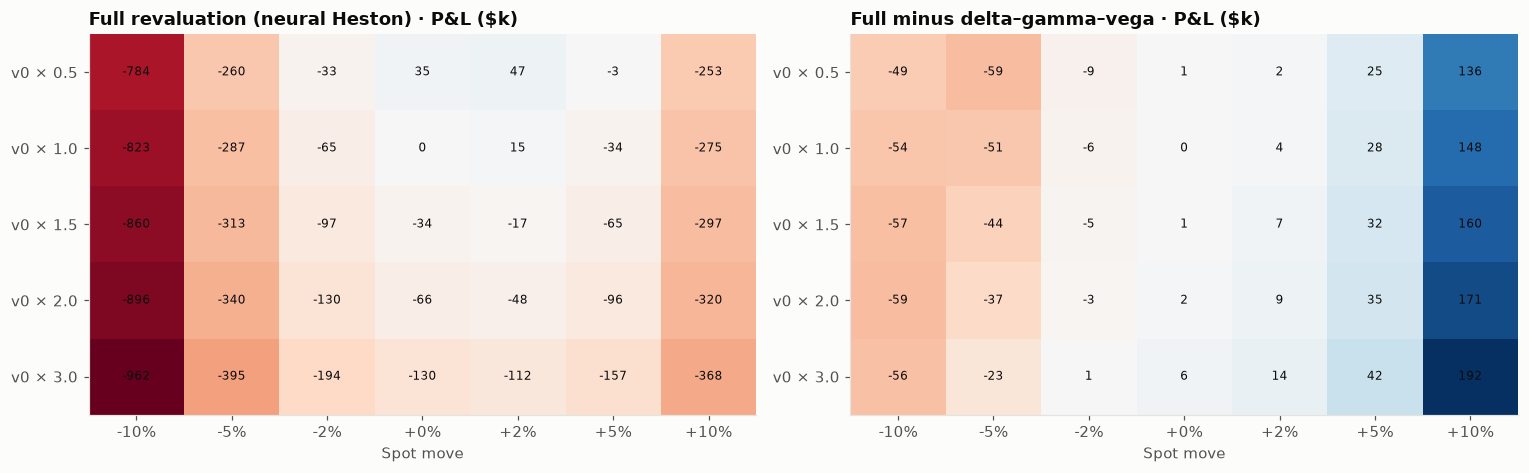

,contracts,type,strike,expiry,T,r
0,-200,put,695.00,20 Nov 26,0.09,0.04
1,-100,put,655.00,15 Jan 27,0.24,0.04
2,150,call,795.00,15 Jan 27,0.24,0.04
3,-150,call,830.00,15 Jan 27,0.24,0.04
4,-100,call,770.00,20 Nov 26,0.09,0.04
5,-100,put,766.00,20 Nov 26,0.09,0.04


In [14]:
def nearest(T_target, k_target, kind):
    o = oh[oh["type"] == kind]
    o = o[(o["T"] - T_target).abs() == (o["T"] - T_target).abs().min()]
    return o.loc[(o["strike"] - k_target).abs().idxmin()]


positions = [
    (-200, nearest(30 / 365, 0.90 * SPOT, "put")),
    (-100, nearest(91 / 365, 0.85 * SPOT, "put")),
    (150, nearest(91 / 365, 1.03 * SPOT, "call")),
    (-150, nearest(91 / 365, 1.08 * SPOT, "call")),
    (-100, nearest(30 / 365, SPOT, "call")),
    (-100, nearest(30 / 365, SPOT * 0.995, "put")),
]
book = pd.DataFrame([
    {
        "contracts": n,
        "type": r_["type"],
        "strike": r_["strike"],
        "expiry": r_["expiry_label"],
        "T": r_["T"],
        "r": r_["r"],
    }
    for n, r_ in positions
])
MULT = 100  # shares per contract


def book_value(S, v0_shift=0.0, dt_years=0.0):
    T = np.maximum(book["T"].values - dt_years, 1 / 365)
    x = torch.tensor(
        np.column_stack([
            S / book["strike"],
            T,
            np.tile(par + np.array([v0_shift, 0, 0, 0, 0]), (len(book), 1)),
        ]),
        requires_grad=True,
    )
    f = net_h(x)
    (gr,) = torch.autograd.grad(f.sum(), x, create_graph=True)
    (fmm,) = torch.autograd.grad(gr[:, 0].sum(), x)
    K, is_p = book["strike"].values, book["type"].values == "put"
    dq, dr = np.exp(-Q * T), np.exp(-book["r"].values * T)
    price = K * f.detach().numpy() - np.where(is_p, S * dq - K * dr, 0)
    delta = gr[:, 0].detach().numpy() - np.where(is_p, dq, 0)
    gamma = fmm[:, 0].numpy() / K
    dv0 = K * gr[:, 2].detach().numpy()
    w = book["contracts"].values * MULT
    return (
        (w * price).sum(),
        (w * delta).sum(),
        (w * gamma).sum(),
        (w * dv0).sum(),
    )


V0, D0, G0, Vv0 = book_value(SPOT)
print(
    f"Book value ${V0:,.0f} · delta {D0:,.0f} shares"
    f" (${D0 * SPOT / 1e6:,.2f}mm) · gamma {G0:,.1f} shares per $ · dV/dv0"
    f" ${Vv0:,.0f} per unit variance (≈"
    f" ${Vv0 * 2 * np.sqrt(HESTON['v0']) / 100:,.0f} per vol point of √v0)"
)

spot_moves = np.array([-0.10, -0.05, -0.02, 0, 0.02, 0.05, 0.10])
# v0 multiplied by 0.5× … 3×
var_moves = np.array([-0.5, 0, 0.5, 1.0, 2.0]) * HESTON["v0"]
full = np.array([
    [book_value(SPOT * (1 + s), dv)[0] - V0 for s in spot_moves]
    for dv in var_moves
])
taylor = np.array([
    [D0 * SPOT * s + 0.5 * G0 * (SPOT * s) ** 2 + Vv0 * dv for s in spot_moves]
    for dv in var_moves
])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, M, title in [
    (axes[0], full, "Full revaluation (neural Heston)"),
    (axes[1], full - taylor, "Full minus delta–gamma–vega"),
]:
    lim = np.abs(M).max()
    im = ax.imshow(
        M / 1e3, cmap="RdBu", vmin=-lim / 1e3, vmax=lim / 1e3, aspect="auto"
    )
    for (i, j), v in np.ndenumerate(M / 1e3):
        ax.text(
            j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8, color=INK
        )
    ax.set_xticks(range(len(spot_moves)), [f"{s:+.0%}" for s in spot_moves])
    ax.set_yticks(
        range(len(var_moves)),
        [f"v0 × {1 + m / HESTON['v0']:.1f}" for m in var_moves],
    )
    ax.set_xlabel("Spot move")
    ax.set_title(f"{title} · P&L ($k)")
    ax.grid(False)
plt.tight_layout()
save_fig(fig, "04_book_scenario_pnl")
plt.show()
book

In [15]:
bs_acc.to_csv(OUT_DIR / "bs_greek_accuracy.csv")
h_acc.to_csv(OUT_DIR / "heston_greek_accuracy.csv")
pd.Series(HESTON).to_csv(OUT_DIR / "heston_calibration.csv")
opts[[
    "expiry_label",
    "T",
    "type",
    "strike",
    "bid",
    "ask",
    "mid",
    "iv",
    "heston_iv",
]].to_csv(OUT_DIR / "spy_chain_iv.csv", index=False)
print(
    "Saved accuracy tables, Heston parameters and the cleaned chain with"
    " implied vols"
)

Saved accuracy tables, Heston parameters and the cleaned chain with implied vols


## 8. Reading the results and limitations

**What to take away**

**Matching prices is not matching Greeks.** The price-only network is decent on prices, but its vega and gamma drift away from the analytic curves, especially in the wings: nothing in its loss controls the derivatives. Training on the derivatives as well (differential ML), with the same network and the same data, cuts the Greek errors two- to five-fold.

For expiries of a month or more, vega and rho errors drop to 1–2% and delta to under 3%. Gamma, a second derivative that is never trained directly, stays the hardest Greek. This is the most important design choice for a neural pricer used in risk.

- **Features matter as much as architecture.** Feeding the networks log-moneyness, total volatility and standardised moneyness, the coordinates in which option prices are smooth, was what took the errors from "interesting" to "usable".

**Heston fits the SPY surface from three weeks out, not the weeklies.** Calibrated on expiries of three weeks or more, it matches the smile within about one vol point, with strongly negative spot–vol correlation and very high vol-of-vol (the Feller condition is violated, as it usually is for equity indices).

For the one- and two-week expiries the error is several vol points: a one-factor diffusion cannot create that much short-dated skew. That is the classic case for jumps or rough volatility (or for fitting the surface without a dynamic model).

- **Speed is the business case.** The network prices a million Heston options, with all first-order Greeks, in seconds. COS needs over two minutes for the prices alone, and bump-and-reprice multiplies that by the number of Greeks. For XVA, initial margin or intraday risk on a large book, that difference decides what is feasible.

**Taylor expansions break down for a short-gamma book.** The scenario grid shows the delta–gamma–vega approximation is close for small moves and off by tens to over a hundred thousand dollars for ±10% moves. The book is short downside puts and short the straddle, so its true losses are not a parabola. Full revaluation, which the network makes cheap, is the answer.

**Limitations**

- **The network is only valid inside its training box.** Inputs outside it, such as a crash scenario that pushes $v_0$ beyond three times today's level, must be detected and sent to the slow pricer.
- **European options only**, with a flat dividend yield and Treasury discounting. SPY options are American, but for out-of-the-money index options the early-exercise premium is small.
- **Snapshot data.** Quotes are not synchronised to the second, and wide quotes in the wings were removed rather than weighted.

## References

### Finance and regulation

- Black, F., & Scholes, M. (1973). The pricing of options and corporate liabilities. *Journal of Political Economy, 81*(3), 637–654. https://doi.org/10.1086/260062
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *The Review of Financial Studies, 6*(2), 327–343. https://doi.org/10.1093/rfs/6.2.327
- Fang, F., & Oosterlee, C. W. (2009). A novel pricing method for European options based on Fourier-cosine series expansions. *SIAM Journal on Scientific Computing, 31*(2), 826–848. https://doi.org/10.1137/080718061

### Machine learning and deep learning

- Huge, B., & Savine, A. (2020). Differential machine learning. *arXiv*. https://arxiv.org/abs/2005.02347
- Hutchinson, J. M., Lo, A. W., & Poggio, T. (1994). A nonparametric approach to pricing and hedging derivative securities via learning networks. *The Journal of Finance, 49*(3), 851–889. https://doi.org/10.1111/j.1540-6261.1994.tb00081.x
- Liu, S., Oosterlee, C. W., & Bohte, S. M. (2019). Pricing options and computing implied volatilities using neural networks. *Risks, 7*(1), 16. https://doi.org/10.3390/risks7010016
- Baydin, A. G., Pearlmutter, B. A., Radul, A. A., & Siskind, J. M. (2018). Automatic differentiation in machine learning: A survey. *Journal of Machine Learning Research, 18*(153), 1–43. https://jmlr.org/papers/v18/17-468.html
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703